# Model prognozowania temperatury z wykorzystaniem CatBoost dla wielu horyzontów czasowych.
W projekcie zastosowano podejście **direct multi-horizon forecasting**, polegające na trenowaniu osobnego modelu dla każdego horyzontu prognozy od 1 do 7 dni.

Dane wejściowe zostały przygotowane na podstawie historycznych wartości temperatury, wilgotności, prędkości wiatru oraz opadów. Wykorzystano również cechy sezonowe (dzień roku, miesiąc oraz transformacje sinus/cosinus) oraz średnie i odchylenia kroczące obliczane wyłącznie na podstawie danych historycznych.

Dane zostały podzielone chronologicznie na zbiór treningowy, walidacyjny oraz testowy, co pozwala uniknąć data leakage i poprawnie odwzorowuje rzeczywisty scenariusz prognozowania.

Dla każdego horyzontu prognozy obliczane są metryki MAE i RMSE, a następnie analizowany jest wpływ długości horyzontu na jakość prognoz.

### Kod realizuje kompletny pipeline prognozowania temperatury z wykorzystaniem modeli CatBoost dla różnych horyzontów czasowych (od 1 do 7 dni do przodu). Całość działa według schematu:

dane historyczne → feature engineering → podział czasowy → trenowanie modeli → prognoza → ocena błędu → wizualizacja

Zdecydowano się na direct multi-horizon forecasting bo recursive forecasting gromadzi błedy.


Trenowanie modelu dla prognozy +1 dni
0:	learn: 8.5941521	test: 8.3277570	best: 8.3277570 (0)	total: 1.86s	remaining: 30m 58s
100:	learn: 2.6303203	test: 2.5881359	best: 2.5881359 (100)	total: 1m 19s	remaining: 11m 45s
200:	learn: 2.5368040	test: 2.5081436	best: 2.5081436 (200)	total: 2m 14s	remaining: 8m 53s
300:	learn: 2.5145383	test: 2.4927718	best: 2.4927718 (300)	total: 3m 5s	remaining: 7m 10s
400:	learn: 2.4991208	test: 2.4826644	best: 2.4826644 (400)	total: 3m 54s	remaining: 5m 50s
500:	learn: 2.4867967	test: 2.4759129	best: 2.4759129 (500)	total: 4m 44s	remaining: 4m 43s
600:	learn: 2.4762049	test: 2.4706615	best: 2.4706615 (600)	total: 5m 33s	remaining: 3m 41s
700:	learn: 2.4663596	test: 2.4671769	best: 2.4671769 (700)	total: 6m 23s	remaining: 2m 43s
800:	learn: 2.4576557	test: 2.4641219	best: 2.4641219 (800)	total: 7m 17s	remaining: 1m 48s
900:	learn: 2.4497954	test: 2.4619007	best: 2.4619007 (900)	total: 8m 14s	remaining: 54.4s
999:	learn: 2.4425980	test: 2.4601164	best: 2.

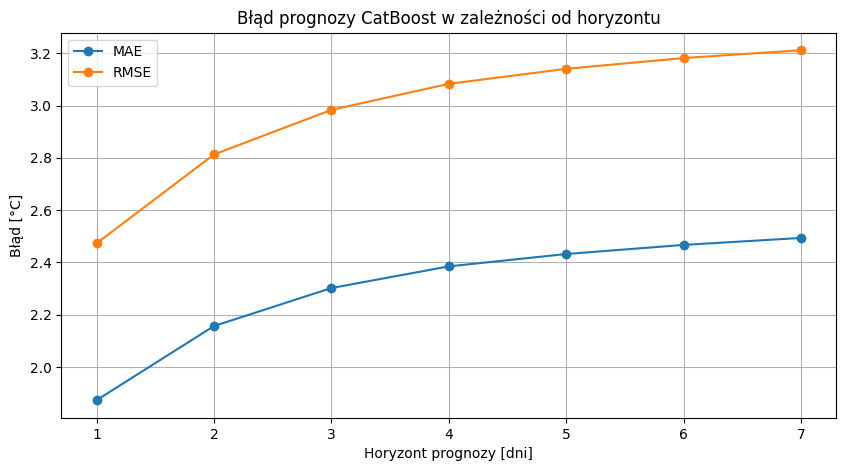

In [1]:
import pandas as pd
import numpy as np

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt


df = pd.read_parquet("era5europa_daily.parquet")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["miasto", "date"]).reset_index(drop=True)


lags = [1, 2, 3, 7, 14, 21, 30, 60, 365]

for lag in lags:
    df[f"temp_lag_{lag}"] = (
        df.groupby("miasto")["tempC_mean"]
        .shift(lag)
    )


df["temp_diff_1_7"] = df["temp_lag_1"] - df["temp_lag_7"]
df["temp_diff_7_14"] = df["temp_lag_7"] - df["temp_lag_14"]
df["temp_diff_7_30"] = df["temp_lag_7"] - df["temp_lag_30"]


windows = [7, 14, 30]

for window in windows:
    df[f"temp_roll_mean_{window}_lag1"] = (
        df.groupby("miasto")["tempC_mean"]
        .transform(lambda x: x.shift(1).rolling(window).mean())
    )

    df[f"temp_roll_std_{window}_lag1"] = (
        df.groupby("miasto")["tempC_mean"]
        .transform(lambda x: x.shift(1).rolling(window).std())
    )


for lag in [1, 2, 3, 7, 14, 30]:
    df[f"humidity_lag_{lag}"] = (
        df.groupby("miasto")["humidity_mean"]
        .shift(lag)
    )

    df[f"wind_lag_{lag}"] = (
        df.groupby("miasto")["windspeed_mean"]
        .shift(lag)
    )

    df[f"tpmm_lag_{lag}"] = (
        df.groupby("miasto")["tpmm_sum"]
        .shift(lag)
    )


features = [
    "miasto",
    "kraj",

    "temp_lag_1",
    "temp_lag_2",
    "temp_lag_3",
    "temp_lag_7",
    "temp_lag_14",
    "temp_lag_21",
    "temp_lag_30",
    "temp_lag_60",
    "temp_lag_365",

    "temp_diff_1_7",
    "temp_diff_7_14",
    "temp_diff_7_30",

    "temp_roll_mean_7_lag1",
    "temp_roll_mean_14_lag1",
    "temp_roll_mean_30_lag1",
    "temp_roll_std_7_lag1",
    "temp_roll_std_14_lag1",
    "temp_roll_std_30_lag1",

    "humidity_lag_1",
    "humidity_lag_2",
    "humidity_lag_3",
    "humidity_lag_7",
    "humidity_lag_14",
    "humidity_lag_30",

    "wind_lag_1",
    "wind_lag_2",
    "wind_lag_3",
    "wind_lag_7",
    "wind_lag_14",
    "wind_lag_30",

    "tpmm_lag_1",
    "tpmm_lag_2",
    "tpmm_lag_3",
    "tpmm_lag_7",
    "tpmm_lag_14",
    "tpmm_lag_30",

    "sin_day",
    "cos_day",
    "sin_month",
    "cos_month",
    "month",
    "dayofyear"
]


cat_features = ["miasto", "kraj"]

models = {}
results = []
predictions_all = []
test_features_all = []


for forecast_horizon in range(1, 8):

    print("\n" + "=" * 60)
    print(f"Trenowanie modelu dla prognozy +{forecast_horizon} dni")
    print("=" * 60)

    df_h = df.copy()

    df_h["target"] = (
        df_h.groupby("miasto")["tempC_mean"]
        .shift(-forecast_horizon)
    )

    df_h["forecast_date"] = df_h["date"] + pd.Timedelta(days=forecast_horizon)

    df_h["dayofyear"] = df_h["forecast_date"].dt.dayofyear
    df_h["month"] = df_h["forecast_date"].dt.month
    df_h["year"] = df_h["forecast_date"].dt.year

    df_h["sin_day"] = np.sin(2 * np.pi * df_h["dayofyear"] / 365)
    df_h["cos_day"] = np.cos(2 * np.pi * df_h["dayofyear"] / 365)

    df_h["sin_month"] = np.sin(2 * np.pi * df_h["month"] / 12)
    df_h["cos_month"] = np.cos(2 * np.pi * df_h["month"] / 12)

    df_model = df_h.dropna(subset=features + ["target"]).copy()

    train = df_model[df_model["forecast_date"] < "2016-01-01"]

    valid = df_model[
        (df_model["forecast_date"] >= "2016-01-01") &
        (df_model["forecast_date"] < "2021-01-01")
    ]

    test = df_model[df_model["forecast_date"] >= "2021-01-01"]

    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.03,
        depth=8,
        l2_leaf_reg=5,
        loss_function="RMSE",
        random_seed=42,
        verbose=100,
        early_stopping_rounds=50
    )

    model.fit(
        train[features],
        train["target"],
        cat_features=cat_features,
        eval_set=(valid[features], valid["target"])
    )

    preds = model.predict(test[features])

    mae = mean_absolute_error(test["target"], preds)
    rmse = np.sqrt(mean_squared_error(test["target"], preds))

    print(f"CatBoost — prognoza +{forecast_horizon} dni")
    print("MAE:", mae)
    print("RMSE:", rmse)

    models[forecast_horizon] = model

    results.append({
        "horyzont": forecast_horizon,
        "MAE": mae,
        "RMSE": rmse,
        "liczba_train": len(train),
        "liczba_valid": len(valid),
        "liczba_test": len(test),
        "best_iteration": model.get_best_iteration()
    })

    temp_predictions = test[["miasto", "kraj", "date", "forecast_date", "target"]].copy()
    temp_predictions["prediction"] = preds
    temp_predictions["horyzont"] = forecast_horizon
    temp_predictions["error"] = temp_predictions["target"] - temp_predictions["prediction"]
    temp_predictions["abs_error"] = np.abs(temp_predictions["error"])

    predictions_all.append(temp_predictions)

    temp_test_features = test[
        ["miasto", "kraj", "date", "forecast_date", "target"] + features
    ].copy()

    temp_test_features["prediction"] = preds
    temp_test_features["horyzont"] = forecast_horizon
    temp_test_features["error"] = temp_test_features["target"] - temp_test_features["prediction"]
    temp_test_features["abs_error"] = np.abs(temp_test_features["error"])

    test_features_all.append(temp_test_features)


results_df = pd.DataFrame(results)
predictions_df = pd.concat(predictions_all, ignore_index=True)
test_features_df = pd.concat(test_features_all, ignore_index=True)

print("\nWyniki dla wszystkich horyzontów:")
print(results_df)





plt.figure(figsize=(10, 5))
plt.plot(results_df["horyzont"], results_df["MAE"], marker="o", label="MAE")
plt.plot(results_df["horyzont"], results_df["RMSE"], marker="o", label="RMSE")
plt.title("Błąd prognozy CatBoost w zależności od horyzontu")
plt.xlabel("Horyzont prognozy [dni]")
plt.ylabel("Błąd [°C]")
plt.xticks(results_df["horyzont"])
plt.legend()
plt.grid(True)
plt.show()

In [3]:
df.head()

,year,month,day,tempC_mean,tempC_min,tempC_max,dewpointC_mean,humidity_mean,tempdewdiff_mean,windspeed_mean,...,tpmm_lag_3,humidity_lag_7,wind_lag_7,tpmm_lag_7,humidity_lag_14,wind_lag_14,tpmm_lag_14,humidity_lag_30,wind_lag_30,tpmm_lag_30
0,1940,1,1,-1.330989,-5.369415,0.640656,-2.106519,94.558838,0.775531,1.664837,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1940,1,2,-5.144735,-7.946594,-1.787567,-6.757645,88.948433,1.612910,1.673642,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1940,1,3,-7.511755,-14.365814,-4.247467,-10.905231,77.884193,3.393477,2.090587,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1940,1,4,-11.802513,-18.183975,-5.796234,-16.020203,72.252663,4.217690,1.560024,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1940,1,5,-7.708565,-13.339111,-2.144318,-11.456021,74.968208,3.747457,2.003845,...,1.741886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
city_metrics = []

for (country, city, horizon), city_df in predictions_df.groupby(
    ["kraj", "miasto", "horyzont"]
):

    mae = mean_absolute_error(
        city_df["target"],
        city_df["prediction"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            city_df["target"],
            city_df["prediction"]
        )
    )

    city_metrics.append({
        "kraj": country,
        "miasto": city,
        "horyzont": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "liczba_obserwacji": len(city_df)
    })

metrics_by_city = pd.DataFrame(city_metrics)

metrics_by_city = metrics_by_city.sort_values(
    ["horyzont", "MAE"]
)

print(metrics_by_city.head())

          kraj     miasto  horyzont       MAE      RMSE  liczba_obserwacji
238     wlochy     naples         1  0.992837  1.309366               1911
56   hiszpania  barcelona         1  1.164435  1.508224               1911
7      francja       nice         1  1.198198  1.551057               1911
42      grecja     patras         1  1.377969  1.778216               1911
245     wlochy       rome         1  1.385314  1.828290               1911


In [7]:
feature_importance_all = []

for horizon, model in models.items():

    importances = model.get_feature_importance()

    temp_importance = pd.DataFrame({
        "horyzont": horizon,
        "feature": features,
        "importance": importances
    })

    temp_importance = temp_importance.sort_values(
        "importance",
        ascending=False
    )

    feature_importance_all.append(temp_importance)

feature_importance_df = pd.concat(
    feature_importance_all,
    ignore_index=True
)

feature_importance_df.head()

,horyzont,feature,importance
0,1,temp_lag_1,60.884112
1,1,temp_roll_mean_14_lag1,6.167663
2,1,temp_roll_mean_7_lag1,5.434510
3,1,cos_day,4.139156
4,1,tpmm_lag_1,3.200910


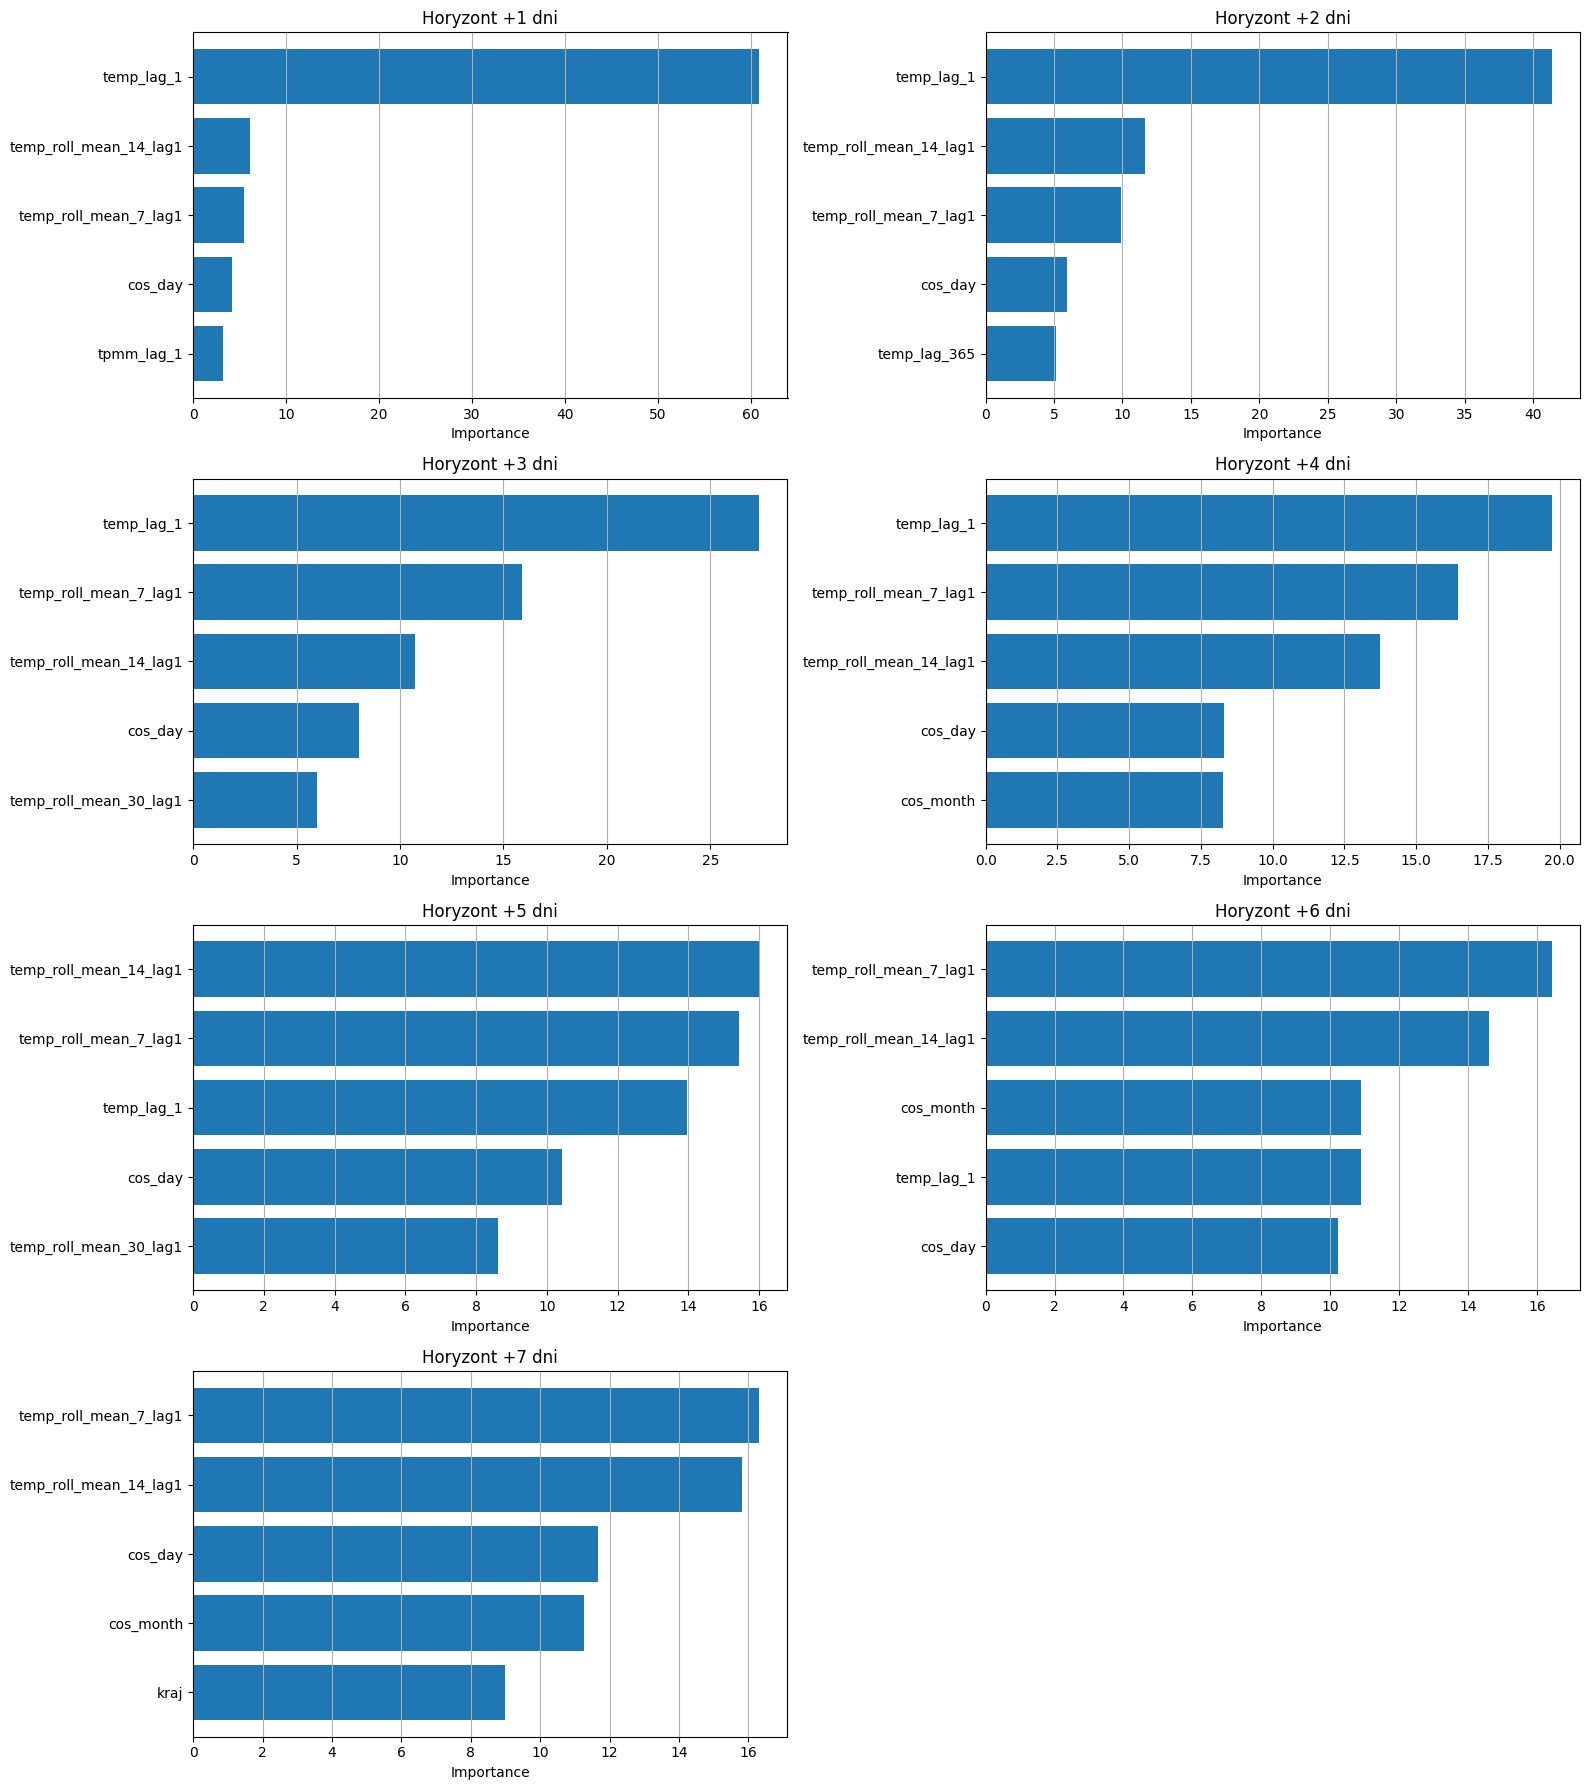

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(16, 18))

axes = axes.flatten()

for idx, horizon in enumerate(range(1, 8)):

    plot_df = (
        feature_importance_df[
            feature_importance_df["horyzont"] == horizon
        ]
        .sort_values("importance", ascending=False)
        .head(5)
        .sort_values("importance")
    )

    axes[idx].barh(
        plot_df["feature"],
        plot_df["importance"]
    )

    axes[idx].set_title(
        f"Horyzont +{horizon} dni"
    )

    axes[idx].set_xlabel("Importance")

    axes[idx].grid(True, axis="x")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

### Zapis wyników do późniejszej wizualizacji

- catboost_results_metrics.csv — metryki MAE/RMSE dla horyzontów, wygląd:

| horyzont | MAE | RMSE |
| -------- | --: | ---: |


- catboost_test_predictions.csv — predykcje na zbiorze testowym, wygląd:

| miasto | date | forecast_date | target | prediction | error |
| ------ | ---- | ------------- | -----: | ---------: | ----: |



- catboost_test_features.csv — zbiór testowy z cechami, lagami i targetem.

In [6]:
results_df.to_csv(
    "catboost_results_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

predictions_df.to_csv(
    "catboost_test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

test_features_df.to_csv(
    "catboost_test_features.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Zapisano pliki:")
print("- catboost_results_metrics.csv")
print("- catboost_test_predictions.csv")
print("- catboost_test_features.csv")

Zapisano pliki:
- catboost_results_metrics.csv
- catboost_test_predictions.csv
- catboost_test_features.csv


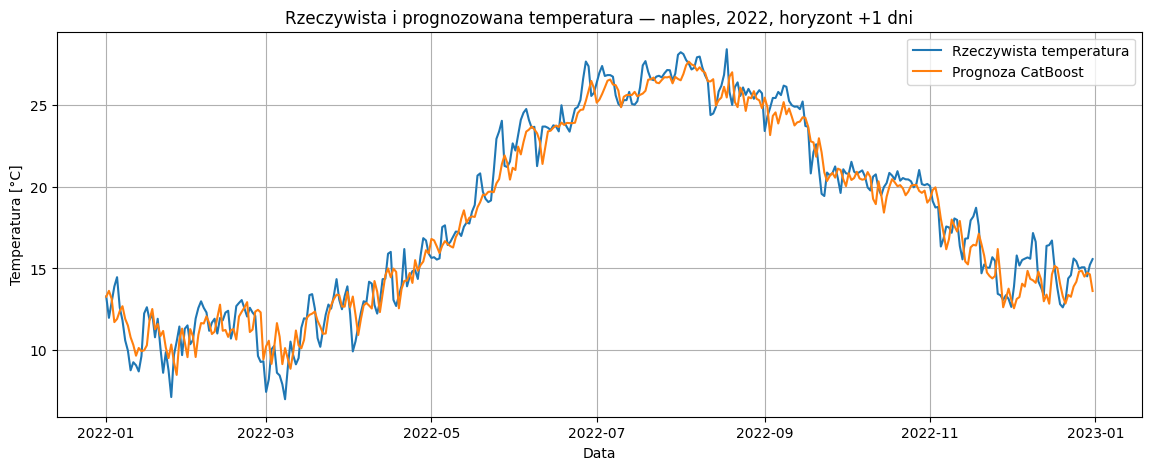

In [9]:
city = "naples"
horizon = 1
year = 2022

plot_df = predictions_df[
    (predictions_df["miasto"] == city) &
    (predictions_df["horyzont"] == horizon) &
    (predictions_df["forecast_date"].dt.year == year)
].sort_values("forecast_date")

plt.figure(figsize=(14, 5))
plt.plot(plot_df["forecast_date"], plot_df["target"], label="Rzeczywista temperatura")
plt.plot(plot_df["forecast_date"], plot_df["prediction"], label="Prognoza CatBoost")

plt.title(f"Rzeczywista i prognozowana temperatura — {city}, {year}, horyzont +{horizon} dni")
plt.xlabel("Data")
plt.ylabel("Temperatura [°C]")
plt.legend()
plt.grid(True)
plt.show()

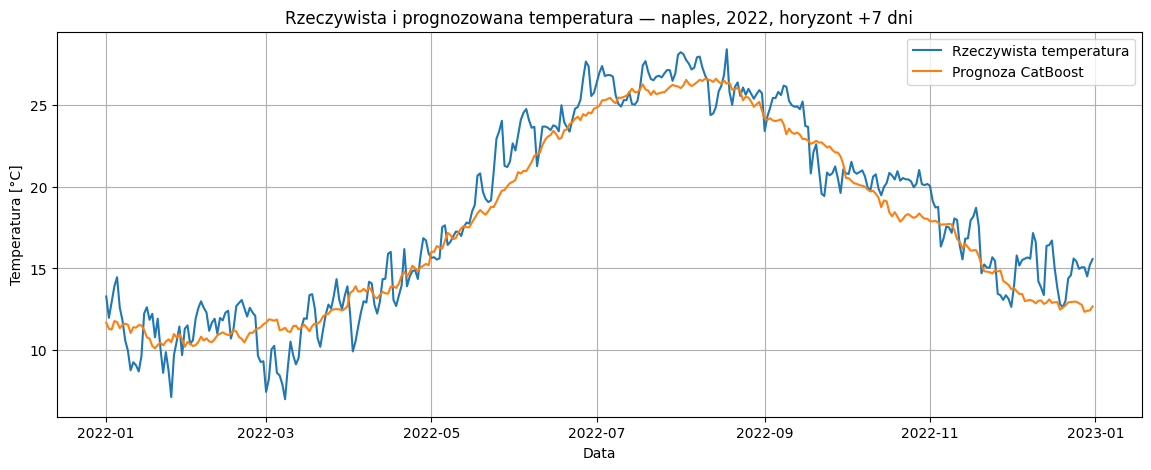

In [10]:
city = "naples"
horizon = 7
year = 2022

plot_df = predictions_df[
    (predictions_df["miasto"] == city) &
    (predictions_df["horyzont"] == horizon) &
    (predictions_df["forecast_date"].dt.year == year)
].sort_values("forecast_date")

plt.figure(figsize=(14, 5))
plt.plot(plot_df["forecast_date"], plot_df["target"], label="Rzeczywista temperatura")
plt.plot(plot_df["forecast_date"], plot_df["prediction"], label="Prognoza CatBoost")

plt.title(f"Rzeczywista i prognozowana temperatura — {city}, {year}, horyzont +{horizon} dni")
plt.xlabel("Data")
plt.ylabel("Temperatura [°C]")
plt.legend()
plt.grid(True)
plt.show()

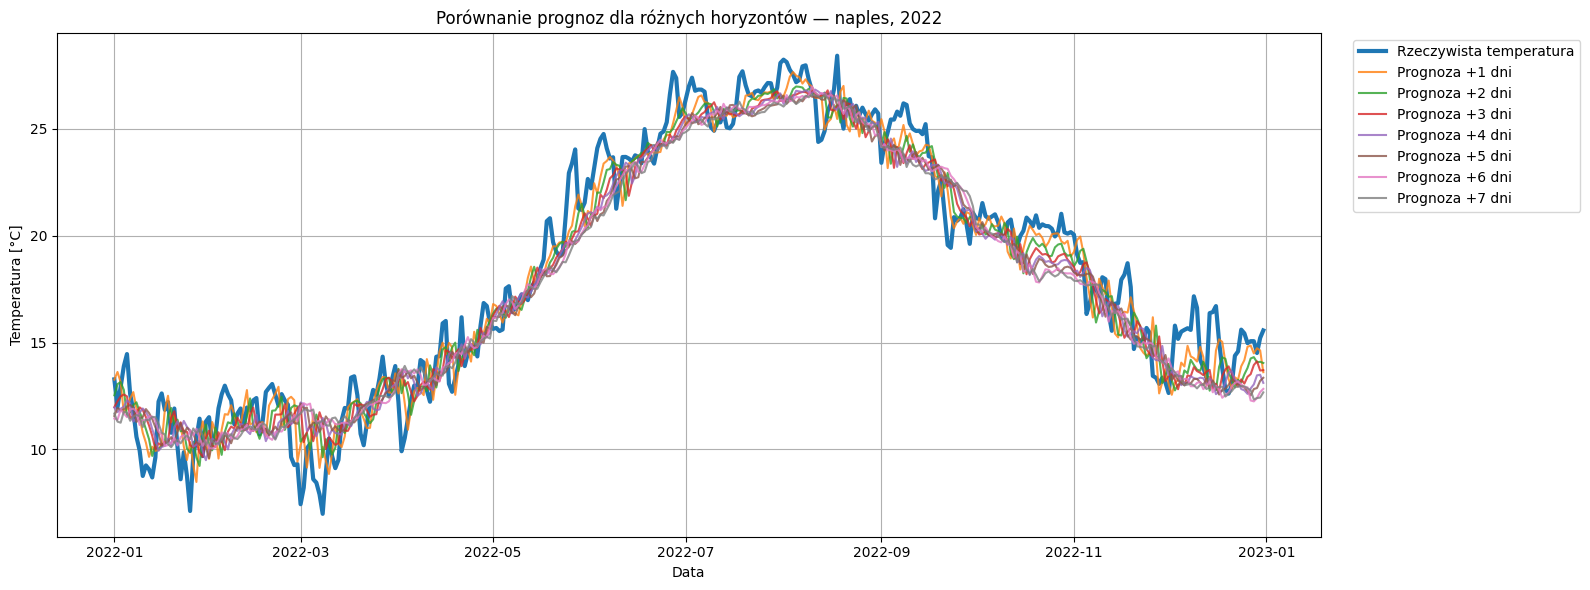

In [11]:
city = "naples"
year = 2022

plt.figure(figsize=(16, 6))

real_df = (
    predictions_df[
        (predictions_df["miasto"] == city) &
        (predictions_df["horyzont"] == 1) &
        (predictions_df["forecast_date"].dt.year == year)
    ]
    .sort_values("forecast_date")
)

plt.plot(
    real_df["forecast_date"],
    real_df["target"],
    linewidth=3,
    label="Rzeczywista temperatura"
)

for horizon in range(1, 8):

    plot_df = (
        predictions_df[
            (predictions_df["miasto"] == city) &
            (predictions_df["horyzont"] == horizon) &
            (predictions_df["forecast_date"].dt.year == year)
        ]
        .sort_values("forecast_date")
    )

    plt.plot(
        plot_df["forecast_date"],
        plot_df["prediction"],
        alpha=0.8,
        label=f"Prognoza +{horizon} dni"
    )

plt.title(
    f"Porównanie prognoz dla różnych horyzontów — {city}, {year}"
)

plt.xlabel("Data")
plt.ylabel("Temperatura [°C]")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True)
plt.tight_layout()
plt.show()

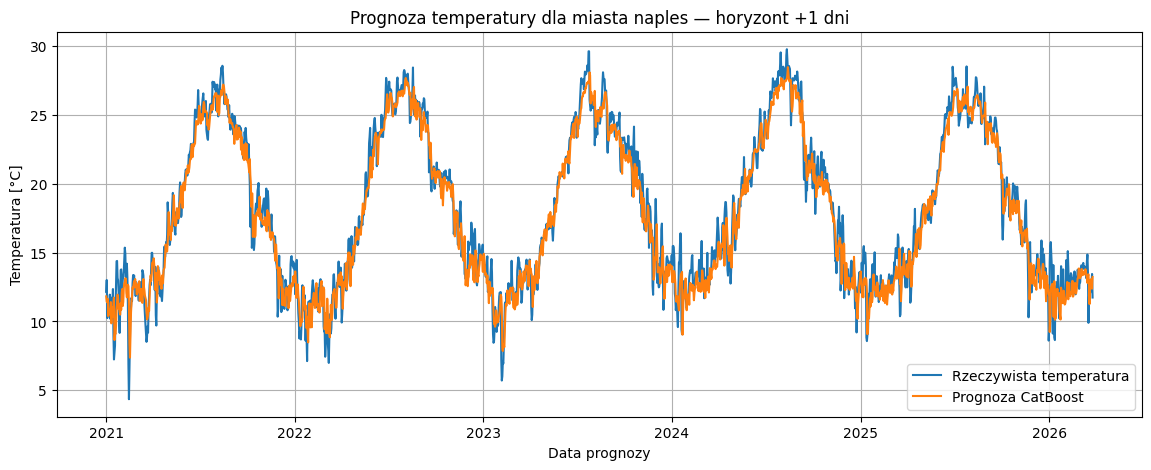

In [12]:
city = "naples"
horizon = 1

plot_df = predictions_df[
    (predictions_df["miasto"] == city) &
    (predictions_df["horyzont"] == horizon)
].sort_values("forecast_date")

plt.figure(figsize=(14, 5))

plt.plot(plot_df["forecast_date"], plot_df["target"], label="Rzeczywista temperatura")
plt.plot(plot_df["forecast_date"], plot_df["prediction"], label="Prognoza CatBoost")

plt.title(f"Prognoza temperatury dla miasta {city} — horyzont +{horizon} dni")
plt.xlabel("Data prognozy")
plt.ylabel("Temperatura [°C]")
plt.legend()
plt.grid(True)
plt.show()

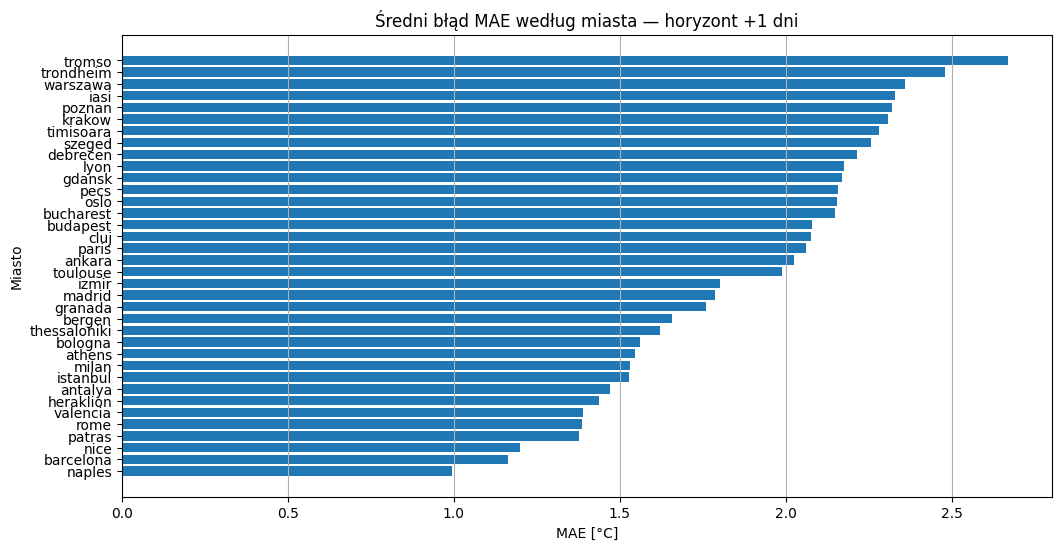

In [13]:
horizon = 1

city_errors = (
    predictions_df
    .groupby(["miasto", "horyzont"])["abs_error"]
    .mean()
    .reset_index()
)

plot_df = city_errors[city_errors["horyzont"] == horizon].sort_values("abs_error")

plt.figure(figsize=(12, 6))
plt.barh(plot_df["miasto"], plot_df["abs_error"])

plt.title(f"Średni błąd MAE według miasta — horyzont +{horizon} dni")
plt.xlabel("MAE [°C]")
plt.ylabel("Miasto")
plt.grid(True, axis="x")
plt.show()

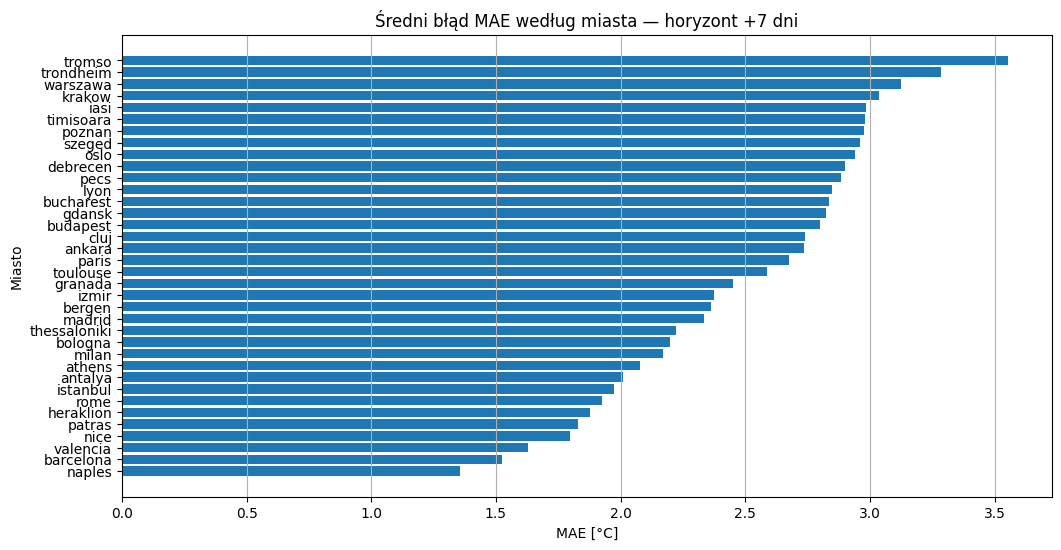

In [14]:
horizon = 7

city_errors = (
    predictions_df
    .groupby(["miasto", "horyzont"])["abs_error"]
    .mean()
    .reset_index()
)

plot_df = city_errors[city_errors["horyzont"] == horizon].sort_values("abs_error")

plt.figure(figsize=(12, 6))
plt.barh(plot_df["miasto"], plot_df["abs_error"])

plt.title(f"Średni błąd MAE według miasta — horyzont +{horizon} dni")
plt.xlabel("MAE [°C]")
plt.ylabel("Miasto")
plt.grid(True, axis="x")
plt.show()

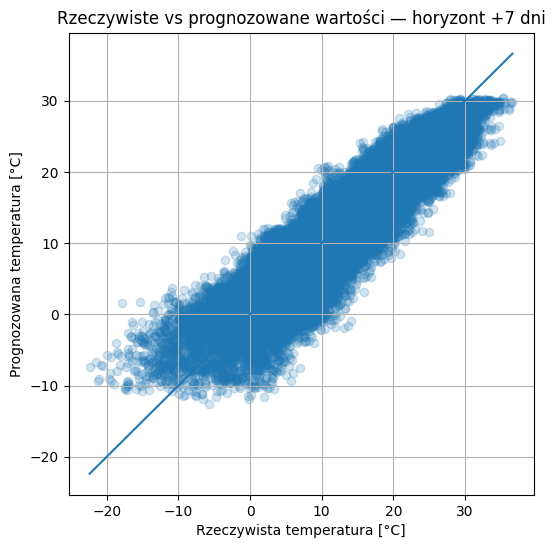

In [15]:
horizon = 7

plot_df = predictions_df[predictions_df["horyzont"] == horizon]

plt.figure(figsize=(6, 6))
plt.scatter(plot_df["target"], plot_df["prediction"], alpha=0.2)

min_val = min(plot_df["target"].min(), plot_df["prediction"].min())
max_val = max(plot_df["target"].max(), plot_df["prediction"].max())

plt.plot([min_val, max_val], [min_val, max_val])

plt.title(f"Rzeczywiste vs prognozowane wartości — horyzont +{horizon} dni")
plt.xlabel("Rzeczywista temperatura [°C]")
plt.ylabel("Prognozowana temperatura [°C]")
plt.grid(True)
plt.show()

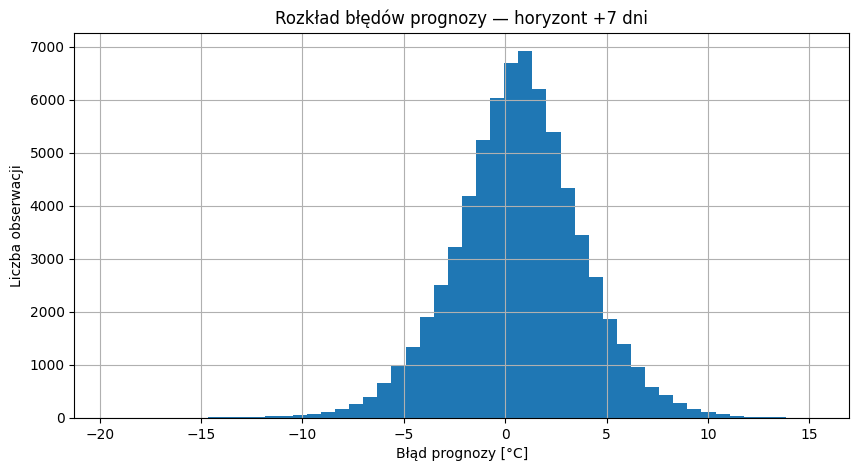

In [16]:
horizon = 7

plot_df = predictions_df[predictions_df["horyzont"] == horizon]

plt.figure(figsize=(10, 5))
plt.hist(plot_df["error"], bins=50)

plt.title(f"Rozkład błędów prognozy — horyzont +{horizon} dni")
plt.xlabel("Błąd prognozy [°C]")
plt.ylabel("Liczba obserwacji")
plt.grid(True)
plt.show()

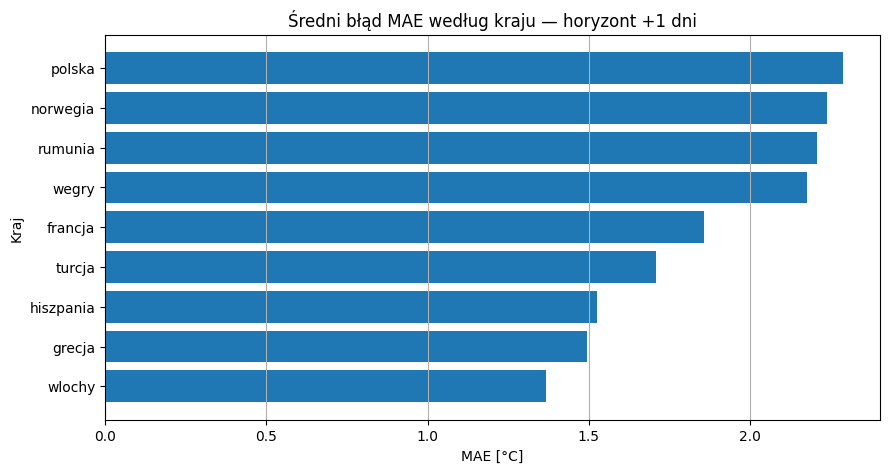

In [17]:
country_errors = (
    predictions_df
    .groupby(["kraj", "horyzont"])["abs_error"]
    .mean()
    .reset_index()
)

horizon = 1

plot_df = country_errors[country_errors["horyzont"] == horizon].sort_values("abs_error")

plt.figure(figsize=(10, 5))
plt.barh(plot_df["kraj"], plot_df["abs_error"])

plt.title(f"Średni błąd MAE według kraju — horyzont +{horizon} dni")
plt.xlabel("MAE [°C]")
plt.ylabel("Kraj")
plt.grid(True, axis="x")
plt.show()

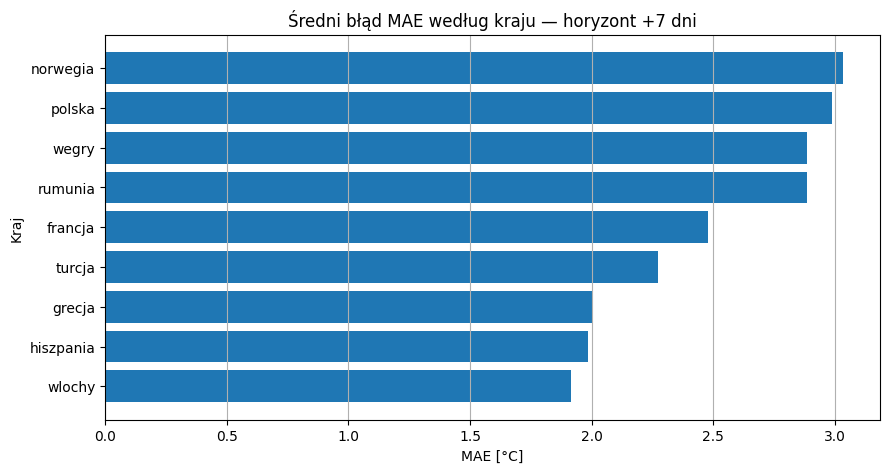

In [20]:
horizon = 7

plot_df = country_errors[country_errors["horyzont"] == horizon].sort_values("abs_error")

plt.figure(figsize=(10, 5))
plt.barh(plot_df["kraj"], plot_df["abs_error"])

plt.title(f"Średni błąd MAE według kraju — horyzont +{horizon} dni")
plt.xlabel("MAE [°C]")
plt.ylabel("Kraj")
plt.grid(True, axis="x")
plt.show()

### Predykcja do dashboardu

In [23]:
future_predictions = []

latest_date = df["date"].max()

print("Ostatnia data w danych:", latest_date)

for horizon in range(1, 8):

    model = models[horizon]

    df_future = df.copy()

    df_future["forecast_date"] = (
        df_future["date"] +
        pd.Timedelta(days=horizon)
    )

    df_future["dayofyear"] = (
        df_future["forecast_date"]
        .dt.dayofyear
    )

    df_future["month"] = (
        df_future["forecast_date"]
        .dt.month
    )

    df_future["sin_day"] = np.sin(
        2 * np.pi * df_future["dayofyear"] / 365
    )

    df_future["cos_day"] = np.cos(
        2 * np.pi * df_future["dayofyear"] / 365
    )

    df_future["sin_month"] = np.sin(
        2 * np.pi * df_future["month"] / 12
    )

    df_future["cos_month"] = np.cos(
        2 * np.pi * df_future["month"] / 12
    )

    latest_rows = df_future[
        df_future["date"] == latest_date
    ].copy()

    latest_rows = latest_rows.dropna(subset=features)

    preds = model.predict(
        latest_rows[features]
    )

    latest_rows["prediction"] = preds
    latest_rows["horyzont"] = horizon

    future_predictions.append(
        latest_rows[
            [
                "kraj",
                "miasto",
                "date",
                "forecast_date",
                "horyzont",
                "prediction"
            ]
        ]
    )

future_predictions_df = pd.concat(
    future_predictions,
    ignore_index=True
)

future_predictions_df

Ostatnia data w danych: 2026-03-26 00:00:00


,kraj,miasto,date,forecast_date,horyzont,prediction
0,turcja,ankara,2026-03-26,2026-03-27,1,8.031206
1,turcja,antalya,2026-03-26,2026-03-27,1,12.964126
2,grecja,athens,2026-03-26,2026-03-27,1,12.334928
3,hiszpania,barcelona,2026-03-26,2026-03-27,1,12.968174
4,norwegia,bergen,2026-03-26,2026-03-27,1,4.505727
...,...,...,...,...,...,...
247,francja,toulouse,2026-03-26,2026-04-02,7,11.192557
248,norwegia,tromso,2026-03-26,2026-04-02,7,0.351210
249,norwegia,trondheim,2026-03-26,2026-04-02,7,5.238915
250,hiszpania,valencia,2026-03-26,2026-04-02,7,14.217806


In [31]:
future_predictions_df.to_csv(
    "catboost_future_7day_forecast.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Zapisano plik:")
print("- catboost_future_7day_forecast.csv")

Zapisano plik:
- catboost_future_7day_forecast.csv


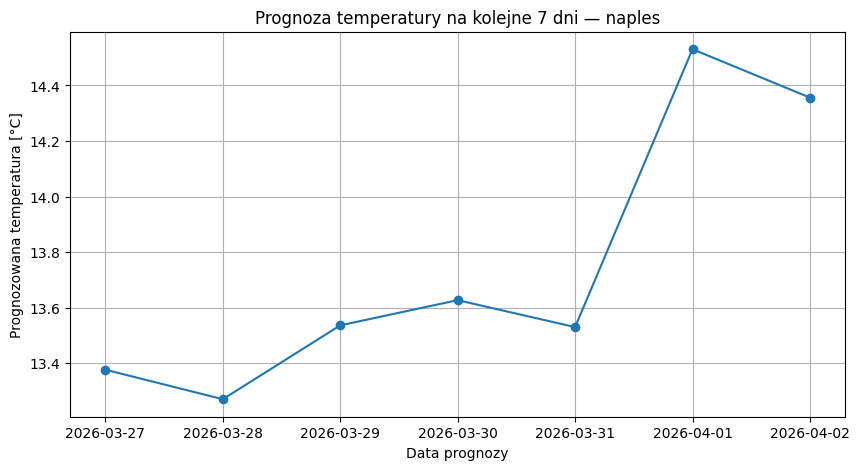

In [27]:
city = "naples"
plot_df = future_predictions_df[
    future_predictions_df["miasto"] == city
].sort_values("forecast_date")

plt.figure(figsize=(10, 5))

plt.plot(
    plot_df["forecast_date"],
    plot_df["prediction"],
    marker="o"
)

plt.title(
    f"Prognoza temperatury na kolejne 7 dni — {city}"
)

plt.xlabel("Data prognozy")
plt.ylabel("Prognozowana temperatura [°C]")

plt.grid(True)
plt.show()

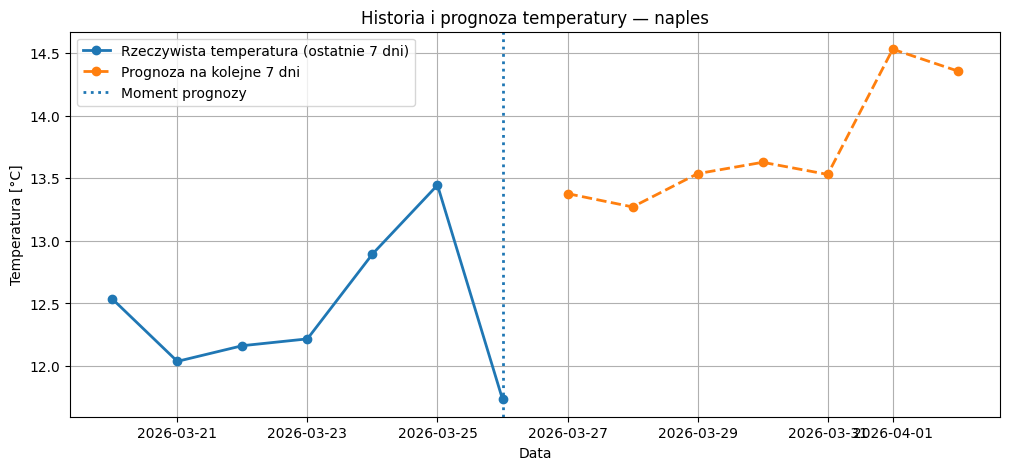

In [30]:
city = "naples"

# prognozy przyszłości
future_plot = (
    future_predictions_df[
        future_predictions_df["miasto"] == city
    ]
    .sort_values("forecast_date")
)

# ostatnie 7 dni rzeczywistych danych
history_plot = (
    df[
        df["miasto"] == city
    ]
    .sort_values("date")
    .tail(7)
)

plt.figure(figsize=(12, 5))

# historia
plt.plot(
    history_plot["date"],
    history_plot["tempC_mean"],
    marker="o",
    linewidth=2,
    label="Rzeczywista temperatura (ostatnie 7 dni)"
)

# prognoza
plt.plot(
    future_plot["forecast_date"],
    future_plot["prediction"],
    marker="o",
    linewidth=2,
    linestyle="--",
    label="Prognoza na kolejne 7 dni"
)

# pionowa linia oddzielająca historię od prognozy
plt.axvline(
    history_plot["date"].max(),
    linestyle=":",
    linewidth=2,
    label="Moment prognozy"
)

plt.title(
    f"Historia i prognoza temperatury — {city}"
)

plt.xlabel("Data")
plt.ylabel("Temperatura [°C]")

plt.legend()
plt.grid(True)

plt.show()